In [1]:
import pandas as pd
dji = pd.read_csv('DJI.csv')
ufo = pd.read_csv('ufo.csv')

In [2]:
dji.head()

,Date,Value
0,1941,110.96
1,1942,119.40
2,1943,135.89
3,1944,152.32
4,1945,192.91


In [3]:
ufo.head()

,Date,Value
0,1941,1
1,1942,2
2,1943,9
3,1944,9
4,1945,9


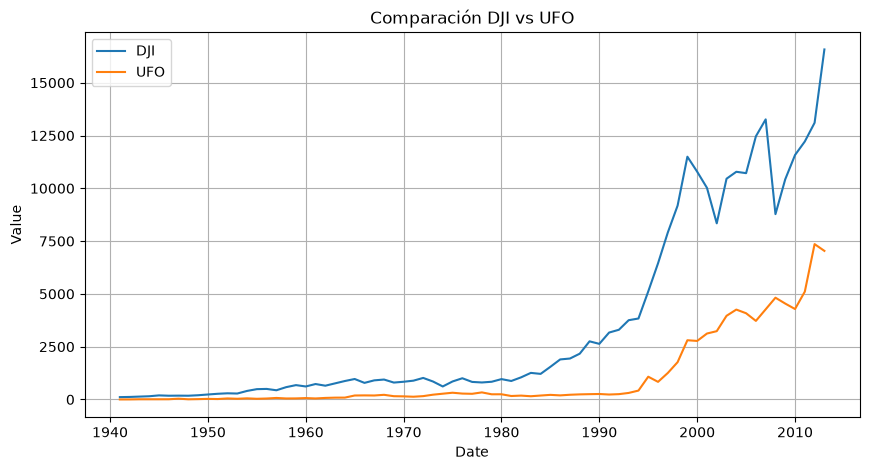

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(dji["Date"], dji["Value"], label="DJI")
plt.plot(ufo["Date"], ufo["Value"], label="UFO")
plt.xlabel("Date")
plt.ylabel("Value")
plt.title("Comparación DJI vs UFO")
plt.legend()
plt.grid(True)
plt.show()

# Correlaciones Espurias

- Dos series con tendencia pueden presentar una alta correlación aún cuando no tinen ninguna relación. (*spurious correlation*) 
- Por ello, en series financieras se analiza la relación de los **rendimientos** y de los **niveles**.

In [5]:
levels = dji.merge(ufo, on="Date", suffixes=("_DJI", "_UFO"))
levels = levels.sort_values(by="Date").reset_index(drop=True)
levels.head()

,Date,Value_DJI,Value_UFO
0,1941,110.96,1
1,1942,119.40,2
2,1943,135.89,9
3,1944,152.32,9
4,1945,192.91,9


## **Cálculo de la correlación**

In [6]:
correlation1 = levels["Value_DJI"].corr(levels["Value_UFO"])
print(f"Correlación entre DJI y UFO: {correlation1:.4f}")

changes = levels.pct_change()
correlation2 = changes["Value_DJI"].corr(changes["Value_UFO"])
print(f"Correlación entre los cambios porcentuales de DJI y UFO: {correlation2:.4f}")   

Correlación entre DJI y UFO: 0.9400
Correlación entre los cambios porcentuales de DJI y UFO: 0.0603


In [7]:
changes.head(20)

,Date,Value_DJI,Value_UFO
0,NaN,NaN,NaN
1,0.000515,0.076063,1.000000
2,0.000515,0.138107,3.500000
3,0.000515,0.120907,0.000000
4,0.000514,0.266478,0.000000
5,0.000514,-0.081437,0.111111
6,0.000514,0.022348,2.700000
7,0.000514,-0.021307,-0.783784
8,0.000513,0.128765,1.000000
9,0.000513,0.176285,0.750000


# Coeficiente de Determinación (R²)
- El **R²** mide que tan bien se ajustan los datos a la recta de regresión.


$$
|\rho_{xy}| = \sqrt{R^2}
$$

In [8]:
import numpy as np
import statsmodels.api as sm

np.random.seed(42)

x = pd.Series(np.random.rand(100), name="x")
y = pd.Series(3*x + np.random.normal(0, 20, 100), name="y")

correlation = x.corr(y)
print(f"Correlación entre x e y: {correlation:.4f}")

X = pd.DataFrame(x)
X = sm.add_constant(X)

model = sm.OLS(y, X)
results = model.fit()

print(results.summary())

Correlación entre x e y: -0.1016
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.022
Date:                Wed, 15 Jul 2026   Prob (F-statistic):              0.315
Time:                        12:34:37   Log-Likelihood:                -430.72
No. Observations:                 100   AIC:                             865.4
Df Residuals:                      98   BIC:                             870.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.30

## Reversión a la Media y Autocorrelación 

In [9]:
msft = pd.read_csv('MSFT.csv')

In [10]:
msft["Date"] = pd.to_datetime(msft["Date"])
msft = msft.set_index("Date")

In [11]:
msft.dtypes

Adj Close    float64
dtype: object

In [12]:
msft = msft.resample(rule='W').last()
returns = msft["Adj Close"].pct_change().dropna()
autocorrelation = returns.autocorr()
print(f"Autocorrelación de los retornos: {autocorrelation:.4f}")

Autocorrelación de los retornos: -0.1568


# Autocorrelación de las Tasas de Interés

In [13]:
daily_rates = pd.read_csv('GS10.csv')
daily_rates.head()

,observation_date,GS10
0,1953-04-01,2.83
1,1953-05-01,3.05
2,1953-06-01,3.11
3,1953-07-01,2.93
4,1953-08-01,2.95


In [14]:
daily_rates.dtypes

observation_date        str
GS10                float64
dtype: object

In [15]:
daily_rates["observation_date"] = pd.to_datetime(daily_rates["observation_date"])
daily_rates = daily_rates.set_index("observation_date")
daily_rates.head()

,GS10
observation_date,
1953-04-01,2.83
1953-05-01,3.05
1953-06-01,3.11
1953-07-01,2.93
1953-08-01,2.95


In [16]:
daily_diff = daily_rates.diff().dropna()
daily_diff.head()

,GS10
observation_date,
1953-05-01,0.22
1953-06-01,0.06
1953-07-01,-0.18
1953-08-01,0.02
1953-09-01,-0.08


In [17]:
autocorrelation_daily_diff = daily_diff["GS10"].autocorr()
print(f"Autocorrelación de los cambios diarios en GS10: {autocorrelation_daily_diff:.4f}")

Autocorrelación de los cambios diarios en GS10: 0.3063


In [18]:
yearly_rates = daily_rates.resample('YE').last()
yearly_diff = yearly_rates.diff().dropna()
autocorrelation_yearly_diff = yearly_diff["GS10"].autocorr()
print(f"Autocorrelación de los cambios anuales en GS10: {autocorrelation_yearly_diff:.4f}")

Autocorrelación de los cambios anuales en GS10: -0.1236


# Función de Autocorrelación

In [19]:
hrb = pd.read_csv('HRB.csv')

In [20]:
hrb.head()

,Quarter,Earnings
0,2007Q1,-0.36
1,2007Q2,-0.38
2,2007Q3,0.07
3,2007Q4,1.85
4,2008Q1,-0.34


In [21]:
hrb["Quarter"] = pd.PeriodIndex(hrb["Quarter"], freq='Q')
hrb = hrb.set_index("Quarter")
hrb.head()

,Earnings
Quarter,
2007Q1,-0.36
2007Q2,-0.38
2007Q3,0.07
2007Q4,1.85
2008Q1,-0.34


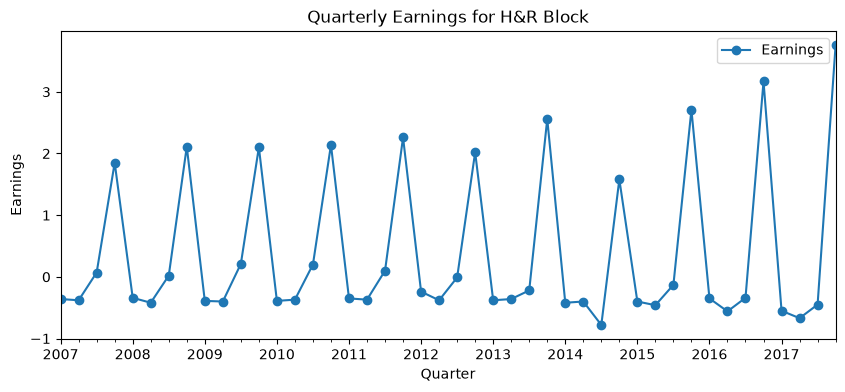

In [22]:
hrb['Earnings'].plot(figsize=(10, 4), marker='o')
plt.title('Quarterly Earnings for H&R Block')
plt.xlabel('Quarter')
plt.ylabel('Earnings')
plt.legend(['Earnings'])
plt.show()

In [23]:
hrb["Earnings"].autocorr(lag=2)

np.float64(-0.44462580750791536)

[ 1.         -0.22122696 -0.39856504 -0.26615093  0.83479804 -0.1901038
 -0.3475634  -0.23140368  0.71995993 -0.15661007 -0.29766783 -0.22097189
  0.61656933 -0.15022869 -0.27922022 -0.22465946  0.5725259 ]


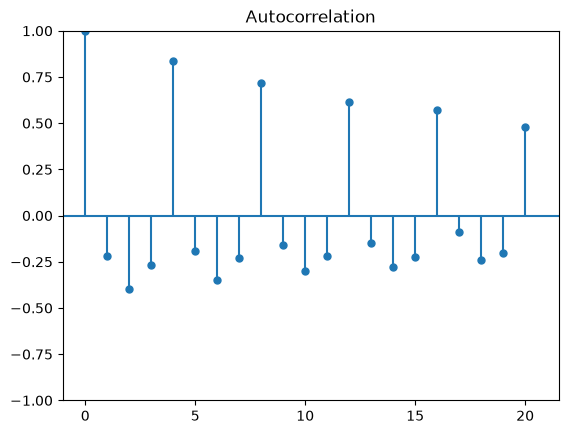

In [24]:
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf

acf_array = acf(hrb["Earnings"])
print(acf_array)
plot_acf(hrb["Earnings"], lags=20, alpha=1)
plt.show()

In [25]:
msft.head()
returns = msft["Adj Close"].pct_change().dropna()
returns.head()

Date
2012-08-19    0.022508
2012-08-26   -0.011003
2012-09-02    0.008508
2012-09-09    0.004218
2012-09-16    0.008400
Freq: W-SUN, Name: Adj Close, dtype: float64

# Significancia de la Autocorrelación

- La autocorrelación muestral puede diferir de cero por efecto del azar.
- Su desviación estándar aproximada es:

$$
\frac{1}{\sqrt{N}}
$$

donde \(N\) es el número de observaciones.

- El intervalo de confianza del 95 % es:

$$
\pm \frac{1.96}{\sqrt{N}}
$$

- En este ejercicio se compara la autocorrelación semanal de MSFT (\(-0.16\)) con este intervalo para determinar si es estadísticamente significativa.

Autocorrelación de los retornos de MSFT: -0.1568
EL intervalo de confianza aproximado es +/- 0.1216


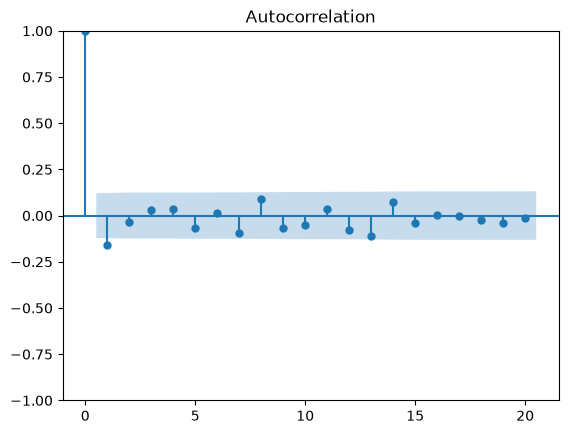

In [26]:
from math import sqrt

autocorrelation_returns = returns.autocorr()
print(f"Autocorrelación de los retornos de MSFT: {autocorrelation_returns:.4f}")
nobs = len(returns)
conf = 1.96/sqrt(nobs)
print(f"EL intervalo de confianza aproximado es +/- {conf:.4f}")
plot_acf(returns, lags=20, alpha=0.05)
plt.show()

# Ruido Blanco

- Media Constante
- Varianza Constante
- Autocorrelación casi igual a cero todos los rezagos

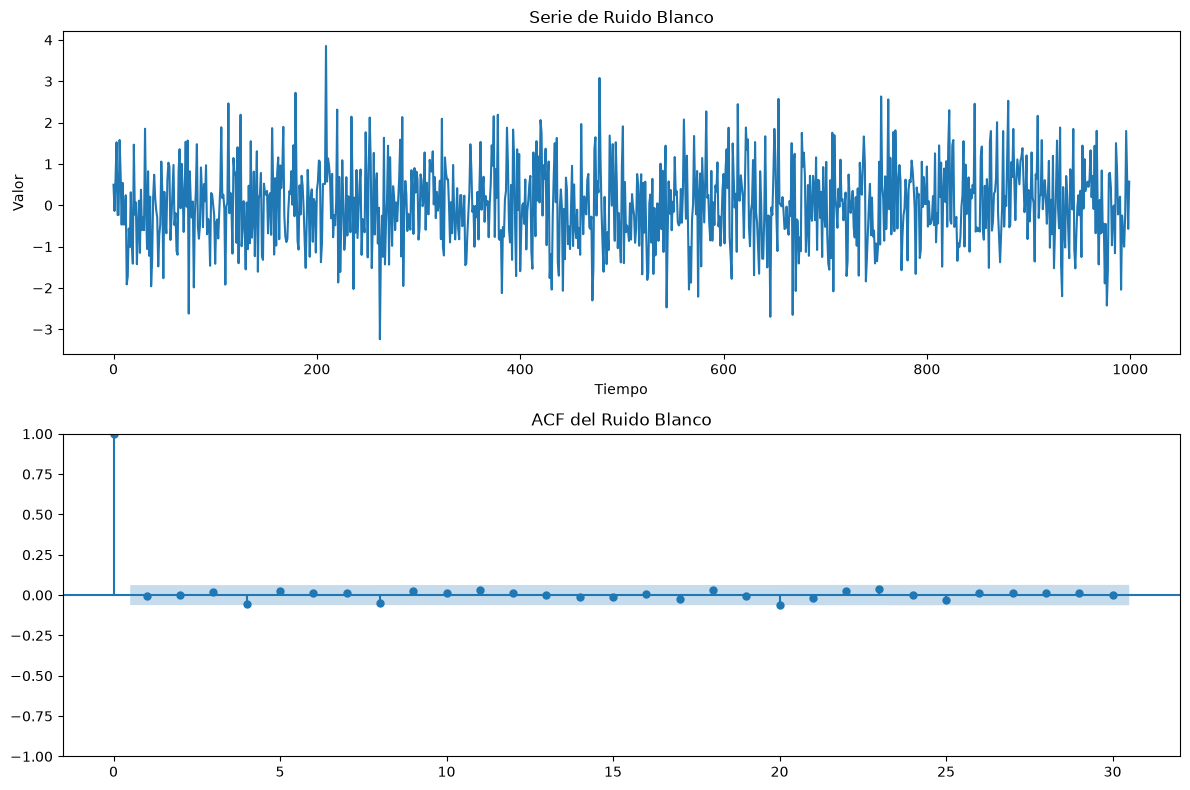

In [27]:
np.random.seed(42)

white_noise = np.random.normal(0, 1, 1000)

# Crear la figura con dos gráficos
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Serie de tiempo
ax[0].plot(white_noise)
ax[0].set_title('Serie de Ruido Blanco')
ax[0].set_xlabel('Tiempo')
ax[0].set_ylabel('Valor')

# Función de autocorrelación
plot_acf(white_noise, lags=30, alpha=0.05, ax=ax[1])
ax[1].set_title('ACF del Ruido Blanco')

plt.tight_layout()
plt.show()



# Caminata aleatoria (Random Walk)


- Un **Random Walk** cumple:

```text
Precio_t = Precio_{t-1} + ruido


- Los **cambios en el precio** (o retornos) son **Ruido Blanco**.

- Un **Random Walk con drift** incluye una tendencia promedio:

```text
Precio_t = Precio_{t-1} + μ + ruido

### Prueba de Random Walk: Dickey-Fuller

- **Hipótesis nula (H₀):** la serie tiene una raíz unitaria y sigue un Random Walk.
- **Hipótesis alternativa (H₁):** la serie es estacionaria.

```python
from statsmodels.tsa.stattools import adfuller

result = adfuller(serie)
p_value = result[1]
```

### Interpretación del p-value

- `p-value < 0.05` → Se rechaza H₀ → La serie **no** es un Random Walk.
- `p-value ≥ 0.05` → No se rechaza H₀ → La serie **puede ser** un Random Walk.

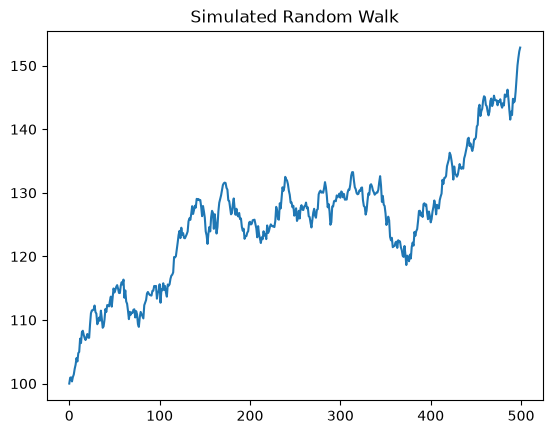

In [28]:
# Generate 500 random steps with mean=0 and standard deviation=1
steps = np.random.normal(loc=0, scale=1, size=500)

# Set first element to 0 so that the first price will be the starting stock price
steps[0]=0

# Simulate stock prices, P with a starting price of 100
P = 100 + np.cumsum(steps)

# Plot the simulated stock prices
plt.plot(P)
plt.title("Simulated Random Walk")
plt.show()

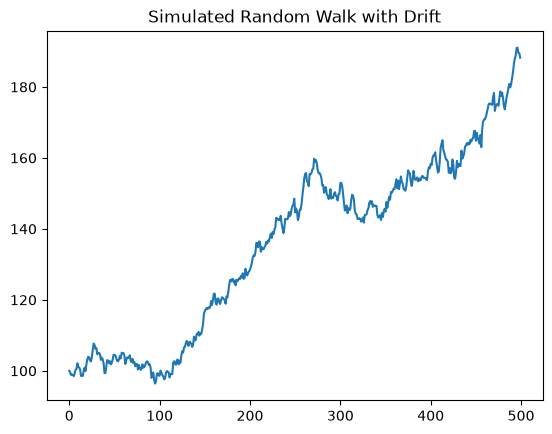

In [29]:
# Generate 500 random steps 
steps = np.random.normal(loc=0.001, scale=0.01, size=500) + 1

# Set first element to 1
steps[0]=1

# Simulate the stock price, P, by taking the cumulative product
P = 100 * np.cumprod(steps)

# Plot the simulated stock prices
plt.plot(P)
plt.title("Simulated Random Walk with Drift")
plt.show()

### ¿Los precios de las acciones siguen una caminata aleatoria?

In [30]:
amzn = pd.read_csv('AMZN.csv')
amzn.head()

,Date,Adj Close
0,5/15/1997,1.958333
1,5/16/1997,1.729167
2,5/19/1997,1.708333
3,5/20/1997,1.635417
4,5/21/1997,1.427083


In [31]:
from statsmodels.tsa.stattools import adfuller

results = adfuller(amzn["Adj Close"])
print(results)

print("El p-valor del test ADF es:", results[1])

(np.float64(4.025168525770739), 1.0, 33, 5054, {'1%': np.float64(-3.4316445438146865), '5%': np.float64(-2.862112049726916), '10%': np.float64(-2.5670745025321304)}, np.float64(30308.64216426981))
El p-valor del test ADF es: 1.0


In [32]:
amzn["Date"] = pd.to_datetime(amzn["Date"])
amzn = amzn.set_index("Date")
amzn_ret = amzn.pct_change().dropna()

results_ret = adfuller(amzn_ret["Adj Close"])
print("El p-valor del test ADF para los retornos es:", results_ret[1])

El p-valor del test ADF para los retornos es: 2.565589808347901e-22


### Stationarity (Estacionariedad)

Una serie es **débilmente estacionaria** si:

- La **media** es constante.
- La **varianza** es constante.
- Las **autocorrelaciones** dependen solo del rezago y no del tiempo.

### ¿Por qué es importante?

La estacionariedad permite construir **modelos parsimoniosos**, es decir, con pocos parámetros y estables en el tiempo.

### Ejemplos de series no estacionarias

- **Random Walk:** la varianza crece con el tiempo.
- **Series estacionales:** la media cambia periódicamente.
- **Series con tendencia:** la media cambia con el tiempo.

### Cómo transformar una serie en estacionaria

- **Primera diferencia** (`X_t - X_{t-1}`):
  - Convierte un Random Walk en una serie estacionaria.

- **Diferencia estacional** (`X_t - X_{t-s}`):
  - Elimina la estacionalidad.

- **Logaritmo + diferencias**:
  - Elimina crecimiento exponencial y estacionalidad.

En muchos casos, una o varias de estas transformaciones permiten convertir una serie no estacionaria en una serie estacionaria.

## Ejercicio: ¿Cuál de las siguientes series es estacionaria?

La figura muestra cuatro series de tiempo simuladas (A, B, C y D).

**Pregunta:** Identifique cuál(es) de las series son estacionarias y justifique su respuesta.

Recuerde que una serie es **estacionaria** si cumple las siguientes propiedades:

- La **media** es aproximadamente constante en el tiempo.
- La **varianza** es aproximadamente constante en el tiempo.
- No presenta **tendencia** ni patrones sistemáticos.

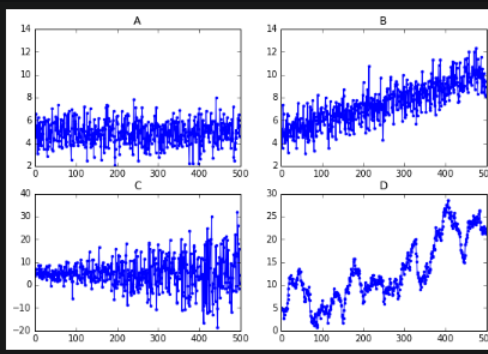

### Opciones

- a) Solo la serie **A** es estacionaria.
- b) Las series **A** y **C** son estacionarias.
- c) Las series **B** y **D** son estacionarias.
- d) Ninguna de las series es estacionaria.

### Ajuste Estacional

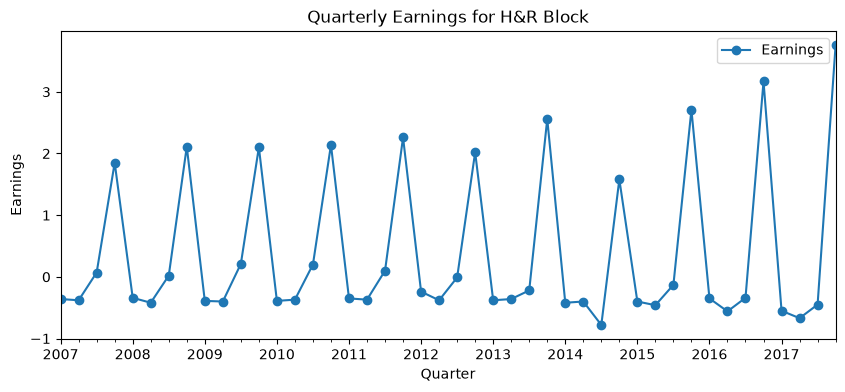

In [33]:
hrb['Earnings'].plot(figsize=(10, 4), marker='o')
plt.title('Quarterly Earnings for H&R Block')
plt.xlabel('Quarter')
plt.ylabel('Earnings')
plt.legend(['Earnings'])
plt.show()

[ 1.         -0.22122696 -0.39856504 -0.26615093  0.83479804 -0.1901038
 -0.3475634  -0.23140368  0.71995993 -0.15661007 -0.29766783 -0.22097189
  0.61656933 -0.15022869 -0.27922022 -0.22465946  0.5725259 ]


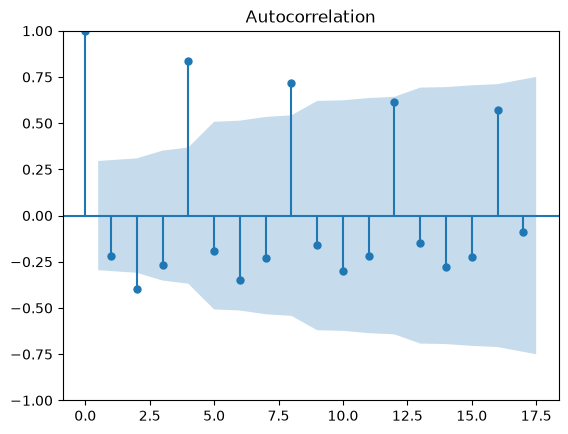

In [34]:
hrb.head()

# Compute the acf array
acf_array = acf(hrb["Earnings"])
print(acf_array)

# Plot the acf
plot_acf(hrb["Earnings"], alpha=0.05)
plt.show()

         Earnings
Quarter          
2008Q1       0.02
2008Q2      -0.04
2008Q3      -0.05
2008Q4       0.26
2009Q1      -0.05
2009Q2       0.02
2009Q3       0.19
2009Q4      -0.01
2010Q1       0.00
2010Q2       0.03


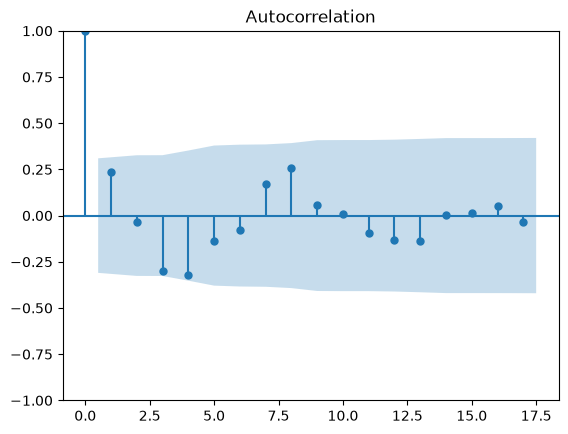

In [35]:
hrbae = hrb.diff(4).dropna()
print(hrbae.head(10))
plot_acf(hrbae)
plt.show()

Text(0, 0.5, 'Seasonally Adjusted Earnings')

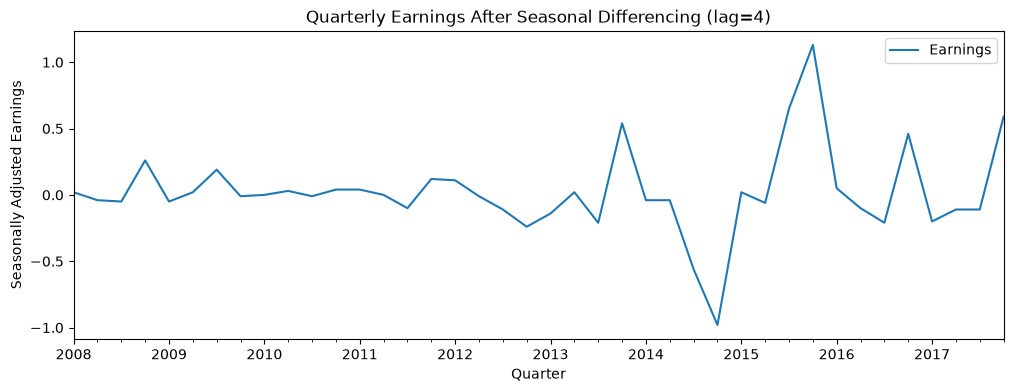

In [36]:
# Graficar la serie transformada
fig, ax = plt.subplots(figsize=(12, 4))

hrbae.plot(ax=ax)

ax.set_title('Quarterly Earnings After Seasonal Differencing (lag=4)')
ax.set_xlabel('Quarter')
ax.set_ylabel('Seasonally Adjusted Earnings')

### Modelo Autorregresivo AR(p)

En un modelo **Autorregresivo (AR)**, el valor actual depende de sus valores pasados y de un término de ruido.

#### Modelo AR(1)

```text
X_t = μ + φ X_{t-1} + ε_t
```

donde:

- `μ` = media de la serie.
- `φ` = parámetro autorregresivo.
- `ε_t` = ruido blanco.

#### Interpretación de `φ`

- `φ = 1` → Random Walk.
- `φ = 0` → Ruido Blanco.
- `-1 < φ < 1` → Serie estacionaria.
- `φ > 0` → Persistencia o **momentum**.
- `φ < 0` → **Reversión a la media (mean reversion)**.

#### Comportamiento de la ACF

- La ACF de un AR(1) **decrece exponencialmente**:

```text
ρ_k = φ^k
```

- Si `φ < 0`, las autocorrelaciones **alternan de signo**.

#### Modelos de orden superior

- **AR(1):** depende de `X_{t-1}`.
- **AR(2):** depende de `X_{t-1}` y `X_{t-2}`.
- **AR(3):** depende de los tres últimos valores.

#### Simulación en Python

Se puede simular un proceso AR usando:

```python
from statsmodels.tsa.arima_process import ArmaProcess
```

y generar muestras con:

```python
ar_process.generate_sample(nsample)
```

### Simulación de un AR(1)

- Un proceso **AR(1)** puede simularse con `ArmaProcess` de `statsmodels`.

- Para un AR(1) con parámetro `φ`, se define:

```python
ar = np.array([1, -φ])
ma = np.array([1])
```

> **Nota:** el signo de `φ` se ingresa con el signo opuesto.

- Crear el proceso:

```python
AR_object = ArmaProcess(ar, ma)
```

- Generar datos simulados:

```python
simulated_data = AR_object.generate_sample(nsample=1000)
```

- Al variar `φ`, cambia el comportamiento de la serie:
  - `φ > 0` → mayor persistencia.
  - `φ < 0` → oscilaciones y reversión a la media.

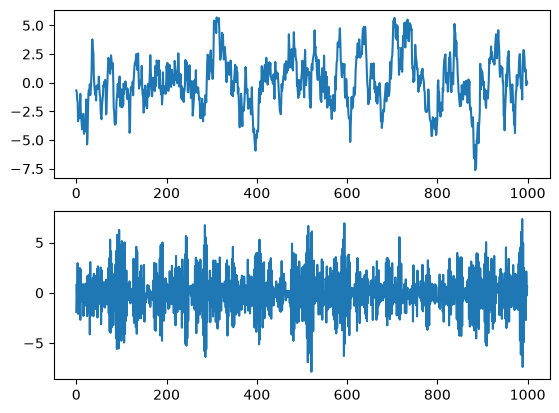

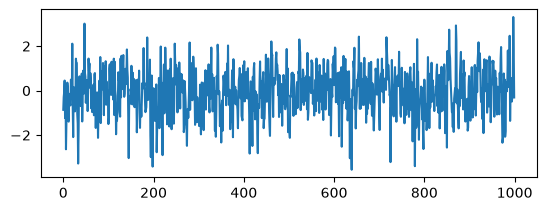

In [37]:
from statsmodels.tsa.arima_process import ArmaProcess

# Plot 1: AR parameter = +0.9
plt.subplot(2,1,1)
ar1 = np.array([1, -0.9])
ma1 = np.array([1])
AR_object1 = ArmaProcess(ar1, ma1)
simulated_data_1 = AR_object1.generate_sample(nsample=1000)
plt.plot(simulated_data_1)

# Plot 2: AR parameter = -0.9
plt.subplot(2,1,2)
ar2 = np.array([1, 0.9])
ma2 = np.array([1])
AR_object2 = ArmaProcess(ar2, ma2)
simulated_data_2 = AR_object2.generate_sample(nsample=1000)
plt.plot(simulated_data_2)
plt.show()

# Plot 3: AR parameter = 0.3
plt.subplot(2,1,2)
ar3 = np.array([1, -0.3])
ma3 = np.array([1])
AR_object3 = ArmaProcess(ar3, ma3)
simulated_data_3 = AR_object3.generate_sample(nsample=1000)
plt.plot(simulated_data_3)
plt.show()


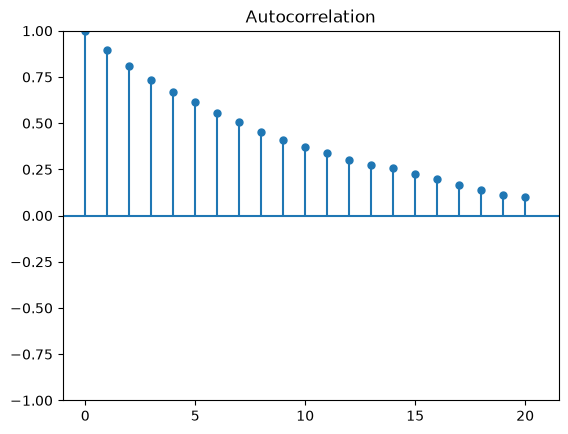

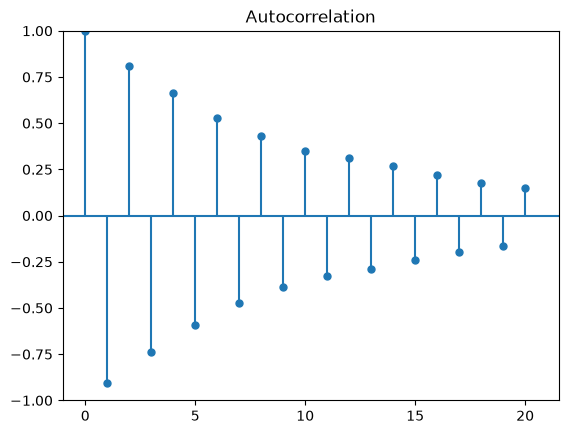

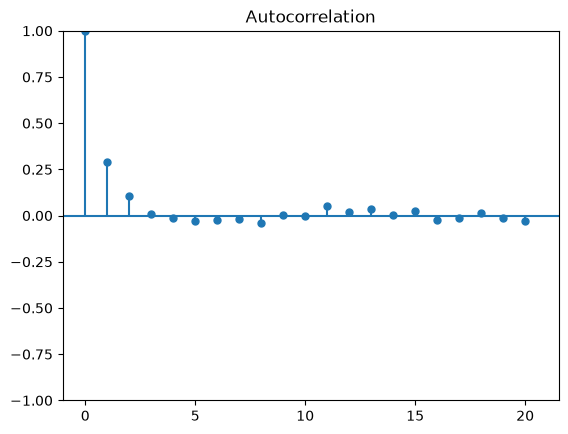

In [38]:
plot_acf(simulated_data_1, lags=20, alpha=1)
plt.show()

plot_acf(simulated_data_2, lags=20, alpha=1)
plt.show()

plot_acf(simulated_data_3, lags=20, alpha=1)
plt.show()

### Pregunta

Observe las siguientes funciones de autocorrelación (ACF).

**¿Cuál de las figuras corresponde a un modelo AR(1) con un parámetro autorregresivo `φ = -0.5`?**

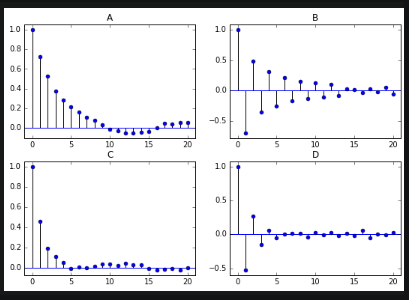

### Estimación y Pronóstico de un modelo autorregresivo

```python
from statsmodels.tsa.arima.model import ARIMA

mod = ARIMA(data, order=(p, d, q))
result = mod.fit()
```


In [39]:
from statsmodels.tsa.arima.model import ARIMA

mod = ARIMA(simulated_data_1, order=(1,0,0))
res = mod.fit()

print(res.summary())

print("El valor real de phi es 0.9 para los datos simulados, y el estimado de phi es:", res.params[1])

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1000
Model:                 ARIMA(1, 0, 0)   Log Likelihood               -1402.384
Date:                Wed, 15 Jul 2026   AIC                           2810.768
Time:                        12:34:38   BIC                           2825.492
Sample:                             0   HQIC                          2816.364
                               - 1000                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0558      0.304      0.184      0.854      -0.540       0.652
ar.L1          0.8977      0.014     64.449      0.000       0.870       0.925
sigma2         0.9658      0.042     23.256      0.0

### Pronóstico con un modelo AR(1)

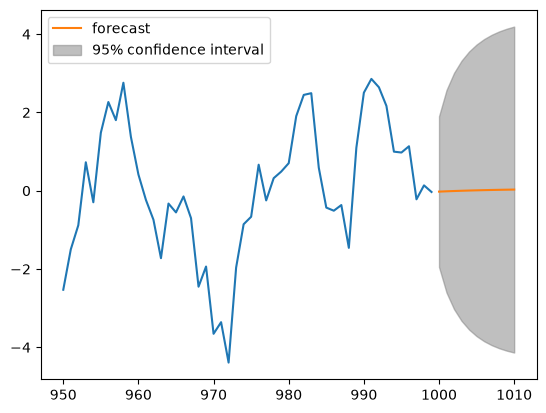

In [40]:
from statsmodels.graphics.tsaplots import plot_predict 

simulated_data_1 = pd.Series(simulated_data_1)
simulated_data_1

mod = ARIMA(simulated_data_1, order=(1,0,0))
res = mod.fit()

fig, ax = plt.subplots()
simulated_data_1.loc[950:].plot(ax=ax)
plot_predict(res, start=1000, end=1010, ax=ax)
plt.show()


### Pronóstico de tasas de interés con un modelo AR(1)

In [41]:
datos_tasas_interes = daily_rates.loc['1962-10-30':'2017-06-21'].resample(rule='YE').last()
datos_tasas_interes.head()

,GS10
observation_date,
1962-12-31,3.86
1963-12-31,4.13
1964-12-31,4.18
1965-12-31,4.62
1966-12-31,4.84


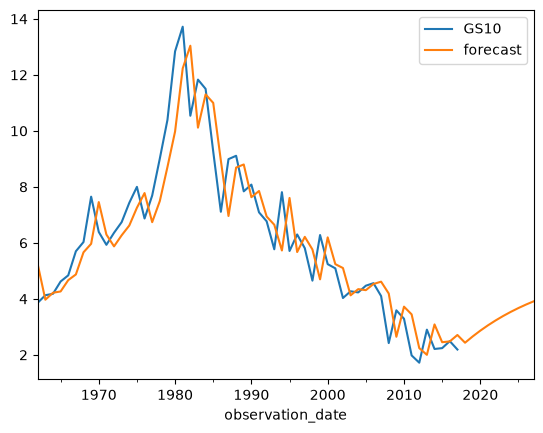

In [42]:
mod = ARIMA(datos_tasas_interes, order=(1,0,0)) # instanciar el modelo
res = mod.fit() # ajustar el modelo a los datos

# Plot the data and the forecast
fig, ax = plt.subplots()
datos_tasas_interes.plot(ax=ax)
plot_predict(res, start=0, end='2027', alpha=None, ax=ax)
plt.show()



### Selección del orden de un modelo autorregresivo AR
Nos vamos a ayudar de dos heramientas!
- PACF (Función de autocorrelación Parcial)
- Criterios de información

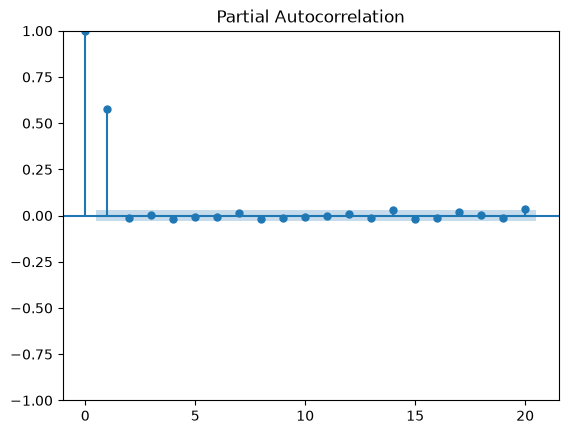

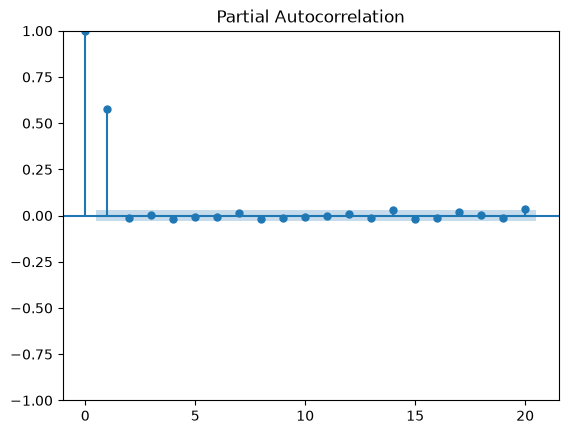

In [43]:
from statsmodels.graphics.tsaplots import plot_pacf

# Simulate AR(1) with phi=+0.6
ma = np.array([1])
ar = np.array([1, -0.6])
AR_object = ArmaProcess(ar, ma)
simulated_data_1 = AR_object.generate_sample(nsample=5000)

plot_pacf(simulated_data_1, lags=20, alpha=0.05)

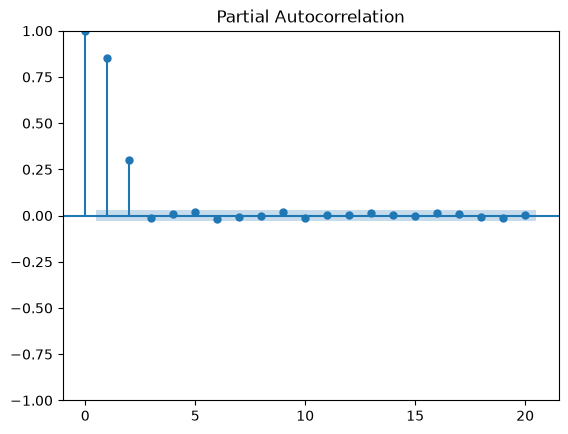

In [44]:
# Simulate AR(2) with phi1=+0.6, phi2=+0.3
ma = np.array([1])
ar = np.array([1, -0.6, -0.3])
AR_object = ArmaProcess(ar, ma)
simulated_data_4 = AR_object.generate_sample(nsample=5000)


# Plot PACF for AR(2)
plot_pacf(simulated_data_4, lags=20)
plt.show()

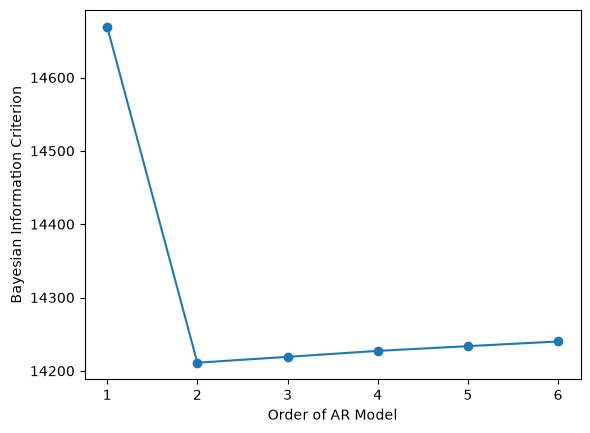

In [45]:
# Import the module for estimating an ARIMA model
from statsmodels.tsa.arima.model import ARIMA

# Fit the data to an AR(p) for p = 0,...,6 , and save the BIC
BIC = np.zeros(7)
for p in range(7):
    mod = ARIMA(simulated_data_4, order=(p,0,0))
    res = mod.fit()
# Save BIC for AR(p)    
    BIC[p] = res.bic
    
# Plot the BIC as a function of p
plt.plot(range(1,7), BIC[1:7], marker='o')
plt.xlabel('Order of AR Model')
plt.ylabel('Bayesian Information Criterion')
plt.show()

### Modelo de Media Móvil MA(q)

En un modelo **Moving Average (MA)**, el valor actual depende del ruido actual y de errores pasados.

#### Modelo MA(1)

```text
X_t = μ + ε_t + θ ε_{t-1}
```

donde:

- `μ` = media de la serie.
- `ε_t` = ruido blanco.
- `θ` = parámetro MA.

#### Interpretación de `θ`

- `θ = 0` → Ruido Blanco.
- `θ > 0` → Autocorrelación positiva en el rezago 1.
- `θ < 0` → Autocorrelación negativa en el rezago 1.

La autocorrelación en el rezago 1 es:

```text
ρ_1 = θ / (1 + θ²)
```

#### Propiedades de la ACF

- En un **MA(1)**, solo el **rezago 1** puede tener autocorrelación distinta de cero.
- Para rezagos mayores:

```text
ρ_k = 0,   para k > 1
```

#### Modelos de orden superior

- **MA(1):** depende de `ε_{t-1}`.
- **MA(2):** depende de `ε_{t-1}` y `ε_{t-2}`.
- **MA(3):** depende de `ε_{t-1}`, `ε_{t-2}` y `ε_{t-3}`.

#### Simulación en Python

```python
from statsmodels.tsa.arima_process import ArmaProcess

ar = np.array([1])
ma = np.array([1, theta])

MA_object = ArmaProcess(ar, ma)
simulated_data = MA_object.generate_sample(nsample=1000)
```

> A diferencia de los modelos AR, en los modelos MA **no es necesario cambiar el signo de `θ`** al definir el arreglo `ma`.

### Simulación de un proceso MA(1)

Un proceso **MA(1)** puede simularse con `ArmaProcess` de `statsmodels`.

Para un parámetro `θ`, se define:

```python
ar = np.array([1])
ma = np.array([1, theta])
```

> A diferencia de los modelos AR, **no se cambia el signo de `θ`**.

Luego se crea el proceso y se generan datos simulados:

```python
MA_object = ArmaProcess(ar, ma)
simulated_data = MA_object.generate_sample(nsample=1000)
```

### Interpretación

- `θ > 0` → la serie muestra una dependencia positiva de corto plazo.
- `θ < 0` → la serie presenta oscilaciones o reversión de corto plazo.
- Al cambiar `θ`, la apariencia de la serie cambia, aunque la principal diferencia se observa en su **función de autocorrelación (ACF)**.

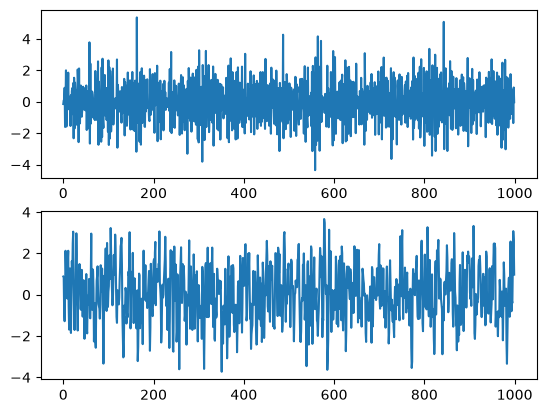

In [46]:
# import the module for simulating data
from statsmodels.tsa.arima_process import ArmaProcess

# Plot 1: MA parameter = -0.9
plt.subplot(2,1,1)
ar1 = np.array([1])
ma1 = np.array([1, -0.9])
MA_object1 = ArmaProcess(ar1, ma1)
simulated_data_1 = MA_object1.generate_sample(nsample=1000)
plt.plot(simulated_data_1)

# Plot 2: MA parameter = +0.9
plt.subplot(2,1,2)
ar2 = np.array([1])
ma2 = np.array([1, 0.9])
MA_object2 = ArmaProcess(ar2, ma2)
simulated_data_2 = MA_object2.generate_sample(nsample=1000)
plt.plot(simulated_data_2)

plt.show()

### ACF de un proceso MA(q)

A diferencia de un modelo AR, la **ACF de un MA(q) se corta después del rezago `q`**.

- **MA(1):** solo el rezago 1 puede ser distinto de cero.
- **MA(2):** solo los rezagos 1 y 2 pueden ser distintos de cero.
- **MA(q):** la ACF es cero para todos los rezagos mayores que `q`.

Para un **MA(1)**:

```text
X_t = μ + ε_t + θ ε_{t-1}
```

la autocorrelación en el rezago 1 es:

```text
ρ_1 = θ / (1 + θ²)
```

y para todos los demás rezagos:

```text
ρ_k = 0,  para k > 1
```

Por ejemplo:

- Si `θ = 0.9`:

```text
ρ_1 = 0.9 / (1 + 0.9²) ≈ 0.497
```

- Si `θ = -0.9`:

```text
ρ_1 = -0.9 / (1 + 0.9²) ≈ -0.497
```

Al graficar la ACF con:

```python
plot_acf(simulated_data_1, lags=20)
```

deberías observar un único pico significativo en el **rezago 1** y autocorrelaciones cercanas a cero para los demás rezagos.

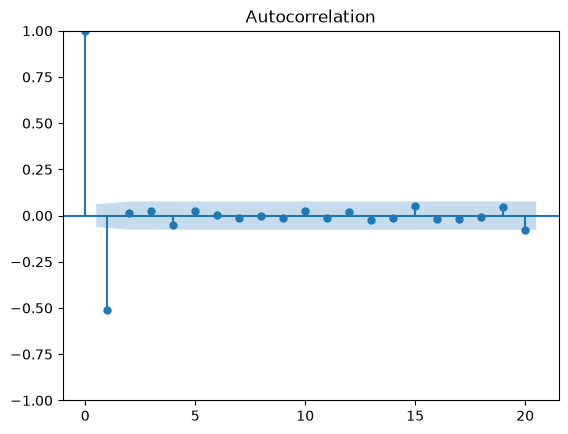

In [47]:
# Import the plot_acf module from statsmodels
from statsmodels.graphics.tsaplots import plot_acf

# Plot 1: MA parameter = -0.9
plot_acf(simulated_data_1, lags=20)
plt.show()

### MA(1) con `θ = 0.9`

```python
plot_acf(simulated_data_2, lags=20)
```

La ACF muestra un **único pico positivo significativo en el rezago 1** y es prácticamente cero para los demás rezagos, comportamiento típico de un **MA(1)**.

---

### MA(1) con `θ = -0.3`

```python
plot_acf(simulated_data_3, lags=20)
```

La ACF muestra un **único pico negativo pequeño en el rezago 1** y es cercana a cero en los demás rezagos, también característico de un **MA(1)**.

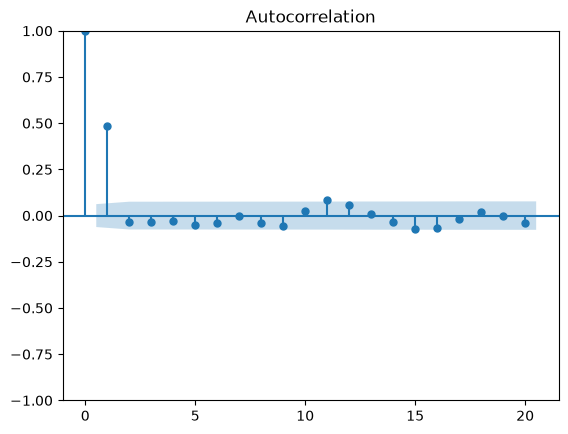

In [48]:
# Plot 2: MA parameter = 0.9
plot_acf(simulated_data_2, lags=20)
plt.show()

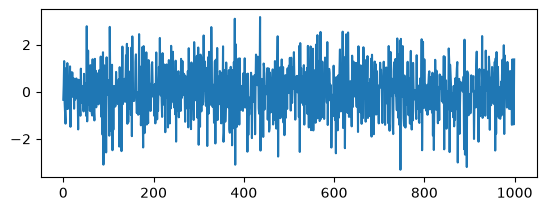

In [49]:
# Plot 3: MA parameter = -0.3
plt.subplot(2,1,1)
ar3 = np.array([1])
ma3 = np.array([1, -0.3])
MA_object3 = ArmaProcess(ar3, ma3)
simulated_data_3 = MA_object3.generate_sample(nsample=1000)
plt.plot(simulated_data_3)

plt.show()

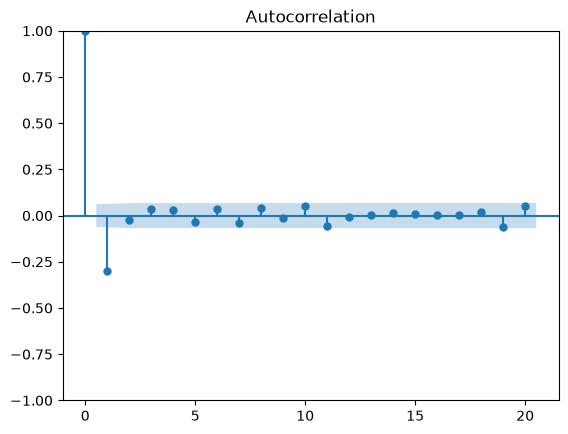

In [50]:
# Plot 3: MA parameter = -0.3
plot_acf(simulated_data_3, lags=20)
plt.show()

### ¿Qué figura corresponde a un modelo MA(1) con un parámetro MA de -0.5?

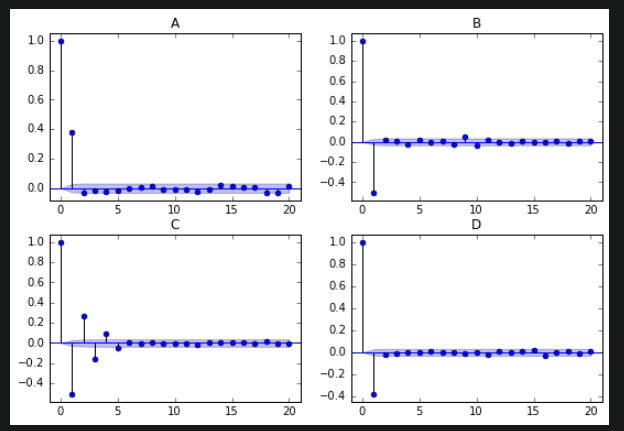

## Respuesta: **Figura D**

### Justificación

Para un modelo **MA(1)** con:

```text
θ = -0.5
```

la autocorrelación en el rezago 1 es:

```text
ρ₁ = θ / (1 + θ²)
    = -0.5 / (1 + 0.25)
    = -0.4
```

y para todos los demás rezagos:

```text
ρ_k = 0,   para k > 1
```

Por lo tanto, la ACF debe mostrar:

- Un **único pico negativo** en el rezago 1 (≈ -0.4).
- Todas las demás autocorrelaciones cercanas a cero.

La única figura que presenta exactamente este comportamiento es la **Figura D**.

> **A = MA(1) con θ positivo (~0.5)**
>
> **D = MA(1) con θ = -0.5**
>
> **B ≈ Ruido blanco**
>
> **C ≈ MA(2)** (hay autocorrelación significativa en más de un rezago).

### Estimación y pronóstico de un modelo MA(1)

Para estimar un **MA(1)** en `statsmodels` se utiliza:

```python
mod = ARIMA(data, order=(0,0,1))
res = mod.fit()
```

donde:

- `p = 0` (sin componente AR)
- `d = 0` (sin diferenciación)
- `q = 1` (componente MA de orden 1)

Para realizar pronósticos se usa:

```python
plot_predict(res, start, end, ax=ax)
```

### Diferencia con un modelo AR

- En un **AR**, los pronósticos convergen gradualmente a la media de largo plazo.
- En un **MA(1)**, **todos los pronósticos a más de un paso adelante son iguales**, ya que el efecto del error pasado desaparece después del primer período.

### Estimación de un modelo MA(1)

Se ajustó un modelo:

```python
ARIMA(simulated_data_1, order=(0,0,1))
```

donde la serie fue simulada con un valor verdadero:

```text
θ = -0.9
```

El modelo estimó:

```text
θ̂ = -0.8967
```

#### Interpretación

- El valor estimado está **muy cerca del verdadero** (`-0.9`), lo que indica que el procedimiento de estimación funciona correctamente.
- El parámetro `ma.L1` es **altamente significativo** (`p-value ≈ 0.000`).
- La constante es cercana a cero y no es significativa (`p-value = 0.818`), como se espera en una serie simulada con media aproximadamente nula.

**Conclusión:** el modelo MA(1) recupera correctamente el parámetro verdadero de la serie simulada.

In [51]:
# Import the ARIMA module from statsmodels
from statsmodels.tsa.arima.model import ARIMA

# Fit an MA(1) model to the first simulated data
mod = ARIMA(simulated_data_1, order=(0,0,1))
res = mod.fit()

# Print out summary information on the fit
print(res.summary())

# Print out the estimate for the constant and for theta
print("When the true theta=-0.9, the estimate of theta is:")
print(res.params[1])

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1000
Model:                 ARIMA(0, 0, 1)   Log Likelihood               -1441.870
Date:                Wed, 15 Jul 2026   AIC                           2889.740
Time:                        12:34:41   BIC                           2904.463
Sample:                             0   HQIC                          2895.335
                               - 1000                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0008      0.003     -0.230      0.818      -0.007       0.006
ma.L1         -0.8964      0.013    -66.436      0.000      -0.923      -0.870
sigma2         1.0452      0.044     23.963      0.0

### Pronóstico con un modelo MA(1)

Para pronosticar un **MA(1)** se ajusta:

```python
ARIMA(data, order=(0,0,1))
```

y se generan pronósticos con:

```python
plot_predict(res, start, end)
```

### Diferencia con un modelo AR(1)

- En un **AR(1)**, los pronósticos convergen gradualmente hacia la media.
- En un **MA(1)**, **todos los pronósticos a más de un período adelante son iguales a la media de la serie**, ya que el efecto del error pasado desaparece después del primer paso.

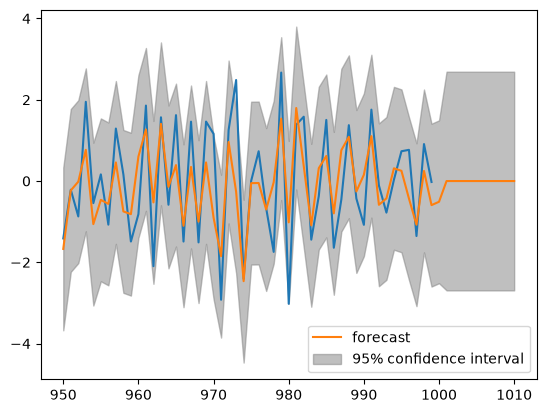

In [52]:
# Import the ARIMA and plot_predict from statsmodels
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_predict


simulated_data_1 = pd.Series(simulated_data_1)
# Forecast the first MA(1) model
mod = ARIMA(simulated_data_1, order=(0,0,1))
res = mod.fit()

# Plot the data and the forecast
fig, ax = plt.subplots()
simulated_data_1.loc[950:].plot(ax=ax)
plot_predict(res, start=950, end=1010, ax=ax)
plt.show()

### Introducción a los modelos ARMA

Un modelo **ARMA(p,q)** combina:

- Un componente **AR(p)** (Autorregresivo).
- Un componente **MA(q)** (Media Móvil).

Por ejemplo, un **ARMA(1,1)** se escribe como:

```text
X_t = μ + φ X_{t-1} + ε_t + θ ε_{t-1}
```

---

### Limpieza de datos intradía de acciones

Para preparar los datos de precios de Sprint:

1. Corregir la primera fecha:

```python
intraday.iloc[0,0] = 0
```

2. Renombrar las columnas:

```python
intraday.columns = ['DATE', 'CLOSE']
```

3. Verificar los tipos de datos:

```python
intraday.dtypes
```

4. Convertir `DATE` a numérico:

```python
intraday['DATE'] = pd.to_numeric(intraday['DATE'])
```

5. Establecer `DATE` como índice:

```python
intraday = intraday.set_index('DATE')
```

El objetivo es dejar la serie lista para el análisis de series de tiempo y el ajuste de modelos MA/ARMA.

In [53]:
import pandas as pd

intraday = pd.read_csv(
    "Sprint_Intraday.txt",
    header=None,
    names=['DATE', 'OPEN', 'HIGH', 'LOW', 'CLOSE', 'VOLUME']
)

intraday.head()

,DATE,OPEN,HIGH,LOW,CLOSE,VOLUME
0,a1504272600,8.2900,8.3000,8.2900,8.30,32407
1,1,8.2700,8.3000,8.2500,8.29,28467
2,2,8.2800,8.2800,8.2800,8.28,1500
3,3,8.2750,8.2800,8.2701,8.28,5200
4,4,8.2875,8.2875,8.2800,8.28,2900


In [54]:
intraday['DATE'] = pd.to_numeric(
    intraday['DATE'].replace('a1504272600', '0')
)
intraday = intraday[['DATE', 'CLOSE']]
intraday.head()

,DATE,CLOSE
0,0,8.30
1,1,8.29
2,2,8.28
3,3,8.28
4,4,8.28


In [55]:
# import datetime module
import datetime

# Change the first date to zero
intraday.iloc[0,0] = 0

# Change the column headers to 'DATE' and 'CLOSE'
intraday.columns = ['DATE','CLOSE']

# Examine the data types for each column
print(intraday.dtypes)

# Convert DATE column to numeric
intraday['DATE'] = pd.to_numeric(intraday['DATE'])

# Make the `DATE` column the new index
intraday = intraday.set_index('DATE')

DATE       int64
CLOSE    float64
dtype: object


### Limpieza de datos intradía con valores faltantes

1. Verificar si faltan minutos de negociación:

```python
len(intraday)
```

2. Identificar los minutos faltantes comparando el índice con el conjunto completo `0,...,390`:

```python
set_missing = set(range(391)) - set(intraday.index)
```

3. Completar las observaciones faltantes usando el último precio disponible (**forward fill**):

```python
intraday = intraday.reindex(range(391), method='ffill')
```

4. Convertir el índice numérico en un índice de fechas y horas reales:

```python
intraday.index = pd.date_range(
    start='2017-09-01 09:30',
    end='2017-09-01 16:00',
    freq='1min'
)
```

5. Graficar la serie:

```python
intraday.plot(grid=True)
plt.show()
```

**Objetivo:** obtener una serie intradía completa y regularmente espaciada para su posterior análisis de series de tiempo.

### 1. Verificar si faltan datos

```python
len(intraday)
```

Un día bursátil tiene **391 minutos** (de 9:30 a 16:00). Si el `DataFrame` tiene menos de 391 filas, significa que hay minutos en los que **no hubo transacciones**.

---

### 2. Encontrar los minutos faltantes

```python
set_everything = set(range(391))
set_intraday = set(intraday.index)
set_missing = set_everything - set_intraday
```

Por ejemplo:

```text
Todos los minutos: {0,1,2,3,4,5,6,7,...,390}
Minutos presentes: {0,1,2,4,5,7,...}
```

La diferencia es:

```text
Minutos faltantes: {3,6,...}
```

---

## ¿Cómo se hace el llenado de datos?

```python
intraday = intraday.reindex(
    range(391),
    method='ffill'
)
```

### Paso 1: `reindex`

Crea un nuevo índice completo:

```text
0,1,2,3,4,5,...,390
```

Los minutos faltantes aparecen como `NaN`.

Por ejemplo:

| índice | CLOSE |
|--------|-------|
| 0 | 8.30 |
| 1 | 8.29 |
| 2 | 8.28 |
| 3 | NaN |
| 4 | 8.28 |

---

### Paso 2: `method='ffill'`

`ffill` (**Forward Fill**) copia el último valor conocido hacia adelante:

| índice | CLOSE |
|--------|-------|
| 0 | 8.30 |
| 1 | 8.29 |
| 2 | 8.28 |
| 3 | 8.28 |
| 4 | 8.28 |

Es decir:

```text
Si no hubo una transacción en un minuto,
se asume que el precio permaneció igual
al último precio negociado.
```

---

### Ejemplo

Antes:

```text
0 → 8.30
1 → 8.29
2 → 8.28
4 → 8.28
```

Después de:

```python
reindex(range(5), method='ffill')
```

queda:

```text
0 → 8.30
1 → 8.29
2 → 8.28
3 → 8.28   ← rellenado
4 → 8.28
```

Este tipo de imputación es muy común en **series financieras de alta frecuencia**, ya que si no hubo operaciones, el mejor estimador del precio es el **último precio observado**.

Si no hubiera datos faltantes, habría 391 filas.
Longitud actual: 389
Minutos faltantes:
[14, 182]
Nueva longitud: 391


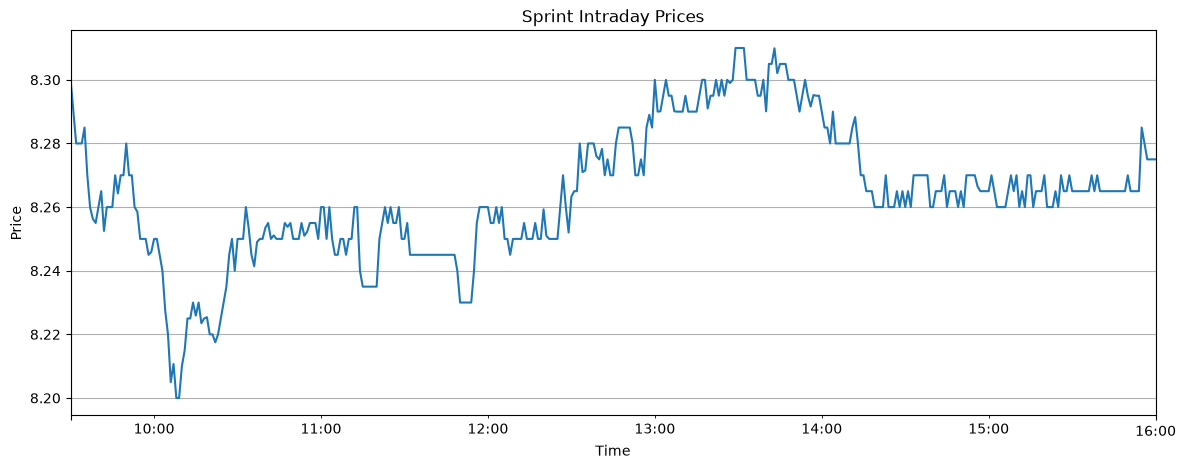

In [56]:
# ==========================
# Verificar longitud
# ==========================
print("Si no hubiera datos faltantes, habría 391 filas.")
print("Longitud actual:", len(intraday))

# ==========================
# Encontrar minutos faltantes
# ==========================
set_everything = set(range(391))
set_intraday = set(intraday.index)
set_missing = set_everything - set_intraday

print("Minutos faltantes:")
print(sorted(set_missing))

# ==========================
# Rellenar minutos faltantes
# ==========================
intraday = intraday.reindex(
    range(391),
    method='ffill'
)

# Verificar nueva longitud
print("Nueva longitud:", len(intraday))

# ==========================
# Crear índice de fechas
# ==========================
intraday.index = pd.date_range(
    start='2017-09-01 09:30',
    end='2017-09-01 16:00',
    freq='1min'
)

# ==========================
# Graficar
# ==========================
intraday.plot(
    figsize=(14, 5),
    grid=True,
    legend=False
)

plt.title('Sprint Intraday Prices')
plt.xlabel('Time')
plt.ylabel('Price')
plt.show()

### Aplicación de un modelo MA(1) a datos intradía

Los precios intradía presentan un fenómeno llamado **bid/ask bounce**, que genera:

- **Autocorrelación negativa en el rezago 1**.
- **Autocorrelaciones cercanas a cero en los demás rezagos**.

Este comportamiento es consistente con un **modelo MA(1)**.

#### Procedimiento

1. Calcular los retornos minuto a minuto:

```python
returns = intraday.pct_change()
returns = returns.dropna()
```

2. Graficar la ACF de los retornos:

```python
plot_acf(returns, lags=60)
plt.show()
```

3. Ajustar un modelo MA(1):

```python
mod = ARIMA(returns, order=(0,0,1))
res = mod.fit()
```

4. Obtener el parámetro estimado:

```python
print(res.params[1])
```

**Objetivo:** verificar que los retornos intradía se comportan aproximadamente como un **MA(1)** con una autocorrelación negativa de corto plazo inducida por el rebote bid/ask.

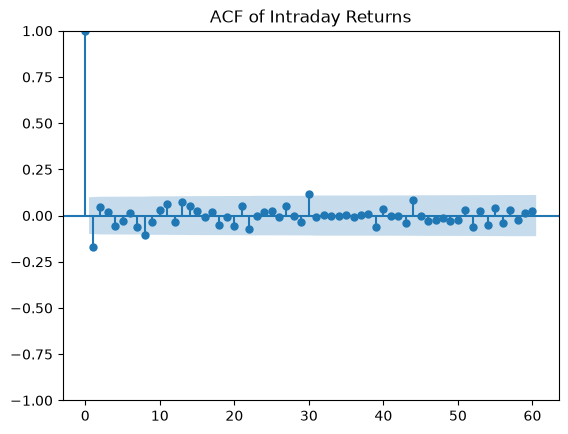

const    -7.509840e-06
ma.L1    -1.783763e-01
sigma2    4.334420e-07
dtype: float64

Estimated theta (MA(1) parameter):
-0.17837626810171053


c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [57]:
# Import plot_acf and ARIMA modules from statsmodels
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt

# ======================================
# Compute returns from prices
# ======================================
returns = intraday.pct_change()
returns = returns.dropna()

# ======================================
# Plot ACF of returns with lags up to 60 minutes
# ======================================
plot_acf(returns, lags=60)
plt.title('ACF of Intraday Returns')
plt.show()

# ======================================
# Fit an MA(1) model
# ======================================
mod = ARIMA(returns, order=(0, 0, 1))
res = mod.fit()

# Print all estimated parameters
print(res.params)

# Print the estimate for theta
print("\nEstimated theta (MA(1) parameter):")
print(res.params['ma.L1'])
# Alternativamente:
# print(res.params.iloc[1])

### ¿Qué es la cointegración?

Dos series pueden seguir un **Random Walk** individualmente, pero si una combinación lineal de ellas:

```text
S_t = P_t - cQ_t
```

es **estacionaria** (presenta reversión a la media), entonces las series están **cointegradas**.

---

### Intuición: el perro y su dueño

- El dueño y el perro pueden caminar de forma aparentemente aleatoria.
- Sin embargo, la distancia entre ellos está limitada por la correa y tiende a volver a un valor normal.

De igual forma:

- `P_t` y `Q_t` → pueden ser Random Walks.
- `P_t - cQ_t` → puede ser estacionaria y revertir a la media.

---

### ¿Dónde aparece la cointegración?

Es común en activos con alguna relación económica:

- Petróleo y gas natural.
- Platino y paladio.
- Maíz y trigo.
- Acciones de empresas del mismo sector (aunque no siempre).

---

### ¿Cómo se prueba la cointegración?

#### Método en dos pasos

1. Regresar una serie sobre la otra:

```text
P_t = a + cQ_t + ε_t
```

2. Aplicar un test ADF a los residuos:

```text
ε_t = P_t - a - cQ_t
```

- Si los residuos son **estacionarios**, las series están cointegradas.
- Si los residuos siguen un **Random Walk**, no hay cointegración.

También puede hacerse directamente con:

```python
from statsmodels.tsa.stattools import coint
```

que realiza ambos pasos automáticamente.

### Ejemplo de cointegración: Heating Oil y Natural Gas

Se grafican las dos series de precios:

```python
plt.plot(7.25*HO)
plt.plot(NG)
```

Ambas parecen seguir un **Random Walk**, por lo que individualmente son difíciles de predecir.

Luego se calcula el **spread**:

```python
Spread = 7.25 * HO - NG
```

y se grafica:

```python
plt.plot(Spread)
plt.axhline(y=0, linestyle='--')
```

### Interpretación

- Si el spread oscila alrededor de una media y muestra **reversión a la media**, existe evidencia de que las series podrían estar **cointegradas**.
- Es decir, aunque cada precio por separado se comporte como un Random Walk, su diferencia mantiene una relación estable de largo plazo.

La gráfica ilustra la analogía del **perro y su dueño unidos por una correa**: ambos pueden moverse aleatoriamente, pero la distancia entre ellos permanece acotada.

In [58]:
HO = pd.read_csv(
    'CME_HO1.csv',
    parse_dates=['Date'],
    index_col='Date'
).sort_index()

NG = pd.read_csv(
    'CME_NG1.csv',
    parse_dates=['Date'],
    index_col='Date'
).sort_index()

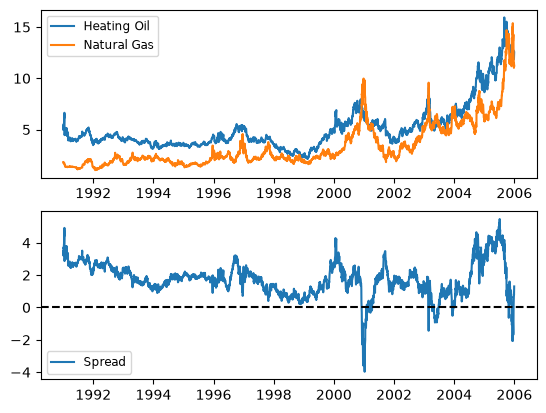

In [59]:
# Plot the prices separately
plt.subplot(2,1,1)
plt.plot(7.25*HO, label='Heating Oil')
plt.plot(NG, label='Natural Gas')
plt.legend(loc='best', fontsize='small')

# Plot the spread
plt.subplot(2,1,2)
plt.plot(7.25 *HO-NG, label='Spread')
plt.legend(loc='best', fontsize='small')
plt.axhline(y=0, linestyle='--', color='k')
plt.show()

### Verificación de cointegración con la prueba ADF

Se aplica la prueba **Augmented Dickey-Fuller (ADF)** a:

1. **Heating Oil (HO)**

```python
adfuller(HO['Close'])
```

2. **Natural Gas (NG)**

```python
adfuller(NG['Close'])
```

3. **El spread**

```python
adfuller(7.25 * HO['Close'] - NG['Close'])
```

### Interpretación

- Si el **p-value > 0.05**, no se rechaza la hipótesis nula de **Random Walk** (serie no estacionaria).
- Si el **p-value < 0.05**, se rechaza la hipótesis nula y la serie es **estacionaria**.

### Resultado esperado

- **HO:** `p-value > 0.05` → Random Walk.
- **NG:** `p-value > 0.05` → Random Walk.
- **Spread:** `p-value < 0.05` → Estacionario.

### Conclusión

Aunque **Heating Oil** y **Natural Gas** son individualmente no estacionarios, su diferencia:

```text
Spread = 7.25 · HO − NG
```

es estacionaria. Por tanto, las dos series están **cointegradas**, es decir, mantienen una relación de equilibrio de largo plazo.

In [60]:
# Import the adfuller module from statsmodels
from statsmodels.tsa.stattools import adfuller

# Compute the ADF for HO and NG
result_HO = adfuller(HO['Close'])
print("The p-value for the ADF test on HO is ", result_HO[1])
result_NG = adfuller(NG['Close'])
print("The p-value for the ADF test on NG is ", result_NG[1])

# Compute the ADF of the spread
result_spread = adfuller(7.25 * HO['Close'] - NG['Close'])
print("The p-value for the ADF test on the spread is ", result_spread[1])

The p-value for the ADF test on HO is  0.9567108785017862
The p-value for the ADF test on NG is  0.9008747444676729
The p-value for the ADF test on the spread is  7.019439302142211e-05


### Interpretación de la prueba ADF

| Serie | p-value | Conclusión |
|-------|----------|------------|
| Heating Oil (HO) | 0.9567 | No se rechaza la hipótesis de Random Walk |
| Natural Gas (NG) | 0.9009 | No se rechaza la hipótesis de Random Walk |
| Spread (7.25·HO − NG) | 0.00007 | Se rechaza la hipótesis de Random Walk |

### ¿Qué significa?

- **HO y NG** tienen p-values muy altos (`> 0.05`), por lo que se comportan como **series no estacionarias (Random Walks)**.
- El **spread** tiene un p-value muy pequeño (`< 0.05`), por lo que es **estacionario** y presenta **reversión a la media**.

### Conclusión

Aunque **Heating Oil** y **Natural Gas** son individualmente impredecibles (Random Walks), su diferencia:

```text
Spread = 7.25 · HO − NG
```

sí es predecible y tiende a volver a un equilibrio de largo plazo.

Por tanto, las dos series están **cointegradas**.

### Caso de estudio: Cambio climático

Se analizará una serie de temperaturas de casi **150 años** utilizando varias técnicas de series de tiempo:

1. **Preparar y visualizar los datos**
   - Convertir el índice a `datetime`.
   - Graficar la serie.

2. **Evaluar estacionariedad**
   - Aplicar la prueba **ADF** para determinar si la serie sigue un Random Walk.

3. **Transformar la serie**
   - Aplicar primeras diferencias para obtener una serie estacionaria.

4. **Analizar dependencias temporales**
   - Calcular la **ACF** y la **PACF**.

5. **Ajustar modelos**
   - Probar modelos **AR**, **MA** y **ARMA**.

6. **Seleccionar el mejor modelo**
   - Comparar los modelos mediante criterios de información (**AIC** y **BIC**).

7. **Realizar pronósticos**
   - Utilizar el mejor modelo para proyectar las temperaturas de los próximos **30 años**.

Este caso integra los principales conceptos del curso: **estacionariedad, diferenciación, ACF/PACF, modelado ARIMA y selección de modelos**.

### ¿La temperatura sigue un Random Walk (con drift)?

1. Convertir el índice de años a fechas:

```python
temp_NY.index = pd.to_datetime(temp_NY.index, format='%Y')
```

2. Graficar la temperatura promedio anual:

```python
temp_NY.plot()
plt.show()
```

3. Aplicar la prueba **Augmented Dickey-Fuller (ADF)**:

```python
result = adfuller(temp_NY['TAVG'])
print(result[1])
```

### Interpretación

- **p-value < 0.05**:
  
  Se rechaza la hipótesis de Random Walk ⇒ la serie es **estacionaria**.

- **p-value > 0.05**:
  
  No se puede rechazar la hipótesis de Random Walk ⇒ la serie es **no estacionaria**.

En este caso, la serie de temperaturas suele presentar una **tendencia de largo plazo (drift)**, por lo que normalmente el test ADF no rechaza la hipótesis de Random Walk y es necesario aplicar **diferenciación** antes de modelarla.

In [61]:
temp_NY = pd.read_csv(
    'NOAA_TAVG.csv',
    parse_dates=['DATE'],
    index_col='DATE'
).sort_index()
temp_NY.head()


,TAVG
DATE,
1870-01-01,53.8
1871-01-01,51.3
1872-01-01,51.3
1873-01-01,50.9
1874-01-01,51.3


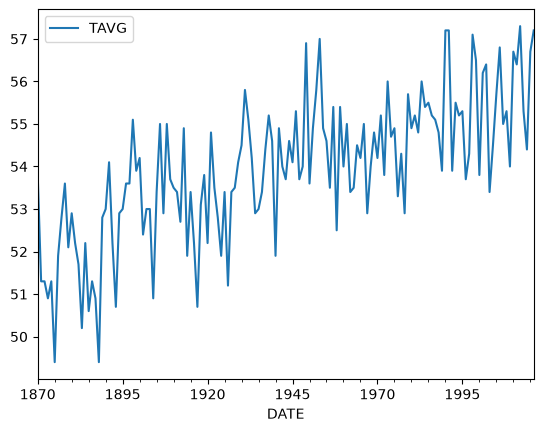

The p-value for the ADF test is  0.583293898787111


In [62]:
# Import the adfuller function from the statsmodels module
from statsmodels.tsa.stattools import adfuller

# Convert the index to a datetime object
temp_NY.index = pd.to_datetime(temp_NY.index, format='%Y')

# Plot average temperatures
temp_NY.plot()
plt.show()

# Compute and print ADF p-value
result = adfuller(temp_NY['TAVG'])
print("The p-value for the ADF test is ", result[1])

### Análisis de autocorrelaciones de la temperatura

Como la serie de temperaturas parece seguir un **Random Walk con drift**, primero se toman **primeras diferencias** para volverla aproximadamente estacionaria:

```python
chg_temp = temp_NY.diff().dropna()
```

Luego se calculan:

- **ACF (Autocorrelation Function)**: mide la correlación con rezagos pasados.
- **PACF (Partial Autocorrelation Function)**: mide la correlación directa con cada rezago, eliminando el efecto de los rezagos intermedios.

```python
plot_acf(chg_temp, lags=20)
plot_pacf(chg_temp, lags=20)
```

### Objetivo

Las gráficas de la **ACF** y la **PACF** sirven para obtener una idea inicial del modelo adecuado:

- PACF que se corta en el rezago `p` → sugiere un **AR(p)**.
- ACF que se corta en el rezago `q` → sugiere un **MA(q)**.
- Si ambas decaen gradualmente → podría ser un **ARMA(p,q)**.

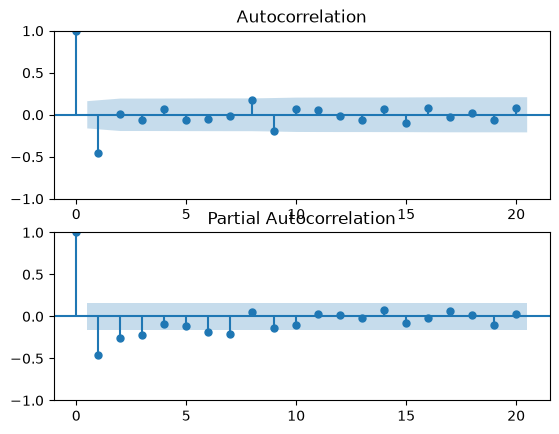

In [63]:
# Import the modules for plotting the sample ACF and PACF
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Take first difference of the temperature Series
chg_temp = temp_NY.diff()
chg_temp = chg_temp.dropna()

# Plot the ACF and PACF on the same page
fig, axes = plt.subplots(2,1)

# Plot the ACF
plot_acf(chg_temp, lags=20, ax=axes[0])

# Plot the PACF
plot_pacf(chg_temp, lags=20, ax=axes[1])
plt.show()

### Selección del mejor modelo con AIC

Se ajustan tres modelos sobre la serie diferenciada `chg_temp`:

| Modelo | Código | Parámetros |
|---------|---------|------------|
| AR(1) | `ARIMA(chg_temp, order=(1,0,0))` | 1 parámetro AR |
| AR(2) | `ARIMA(chg_temp, order=(2,0,0))` | 2 parámetros AR |
| ARMA(1,1) | `ARIMA(chg_temp, order=(1,0,1))` | 1 AR + 1 MA |

El criterio de selección es el **Akaike Information Criterion (AIC)**:

```text
Menor AIC ⇒ Mejor equilibrio entre ajuste y complejidad.
```

### Procedimiento

```python
print(res_ar1.aic)
print(res_ar2.aic)
print(res_arma11.aic)
```

### Regla de decisión

```text
Seleccionar el modelo con el AIC más bajo.
```

El AIC penaliza los modelos con más parámetros para evitar el **sobreajuste (overfitting)**, por lo que un modelo más complejo solo será preferido si mejora suficientemente el ajuste de los datos.

In [64]:
# Import the module for estimating an ARIMA model
from statsmodels.tsa.arima.model import ARIMA

# Fit the data to an AR(1) model and print AIC:
mod_ar1 = ARIMA(chg_temp, order=(1,0,0))
res_ar1 = mod_ar1.fit()
print("The AIC for an AR(1) is: ", res_ar1.aic)

# Fit the data to an AR(2) model and print AIC:
mod_ar2 = ARIMA(chg_temp, order=(2,0,0))
res_ar2 = mod_ar2.fit()
print("The AIC for an AR(2) is: ", res_ar2.aic)

# Fit the data to an ARMA(1,1) model and print AIC:
mod_arma11 = ARIMA(chg_temp, order=(1,0,1))
res_arma11 = mod_arma11.fit()
print("The AIC for an ARMA(1,1) is: ", res_arma11.aic)


The AIC for an AR(1) is:  510.5346898733109
The AIC for an AR(2) is:  501.9274123409139
The AIC for an ARMA(1,1) is:  469.072918920053


c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\P

### Comparación de modelos usando AIC

| Modelo | AIC |
|---------|-----|
| AR(1) | 510.53 |
| AR(2) | 501.93 |
| ARMA(1,1) | 469.07 |

### Interpretación

El criterio **AIC** selecciona el modelo que logra el mejor equilibrio entre:

- **Buen ajuste a los datos**.
- **Menor complejidad del modelo**.

La regla es:

```text
Menor AIC ⇒ Mejor modelo.
```

Como:

```text
469.07 < 501.93 < 510.53
```

el **ARMA(1,1)** es claramente el mejor de los tres modelos considerados.

### Conclusión

La serie de cambios anuales de temperatura presenta una dinámica que no puede ser explicada únicamente por un componente autorregresivo (AR), sino que también requiere un componente de media móvil (MA). Por ello, el modelo seleccionado es:

```text
ARMA(1,1)
```

### Pronóstico de temperaturas con un modelo ARIMA(1,1,1)

Como la serie de temperaturas original es un **Random Walk con drift**, se modela con un:

```text
ARIMA(1,1,1)
```

donde:

- **p = 1:** un término autorregresivo (AR).
- **d = 1:** se toma una primera diferencia para hacer la serie estacionaria.
- **q = 1:** un término de media móvil (MA).

Además, se incluye una **tendencia lineal**:

```python
trend='t'
```

para capturar el aumento gradual de las temperaturas a lo largo del tiempo.

---

### Código

```python
mod = ARIMA(temp_NY, trend='t', order=(1,1,1))
res = mod.fit()

fig, ax = plt.subplots()
temp_NY.plot(ax=ax)
plot_predict(res, start='1872', end='2046', ax=ax)
plt.show()
```

---

### Interpretación del gráfico

- La línea de pronóstico muestra la **evolución esperada de la temperatura** hasta el año 2046.
- La banda sombreada representa el **intervalo de confianza** del pronóstico.
- La tendencia de largo plazo está determinada principalmente por el **drift (tendencia)**, más que por los parámetros AR y MA.

### Conclusión

El modelo predice que las temperaturas continuarán siguiendo una **tendencia ascendente**, aunque la incertidumbre del pronóstico aumenta a medida que se proyecta más lejos en el futuro.

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)


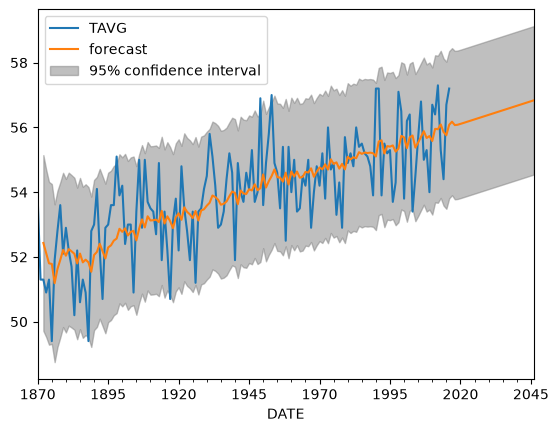

In [65]:
# Import the ARIMA module from statsmodels
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_predict

# Forecast temperatures using an ARIMA(1,1,1) model
mod = ARIMA(temp_NY, trend='t', order=(1,1,1))
res = mod.fit()

# Plot the original series and the forecasted series
fig, ax = plt.subplots()
temp_NY.plot(ax=ax)
plot_predict(res, start='1872', end='2046', ax=ax)
plt.show()